# Lecture 1 author-facing figure notebook: coin model

This notebook regenerates the coin-model figures used in `slide_deck.typ`.

It follows the course figure convention:

- the notebook lives in the lecture directory;
- generated assets go in `figures/`;
- each filename is `<notebook-stem>__<figure-name>.svg`;
- the figure path is shown on the slide as provenance.

Conceptual sequence:

1. Beta distributions over the coin bias
2. Bernoulli likelihood for one observed toss
3. Beta prior + binomial likelihood → posterior
4. Sequential updating under different priors
5. Posterior → posterior predictive distribution
6. Posterior sampling → Monte Carlo approximation


In [13]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, binom, betabinom

# Reproducibility
RNG = np.random.default_rng(4361)

# Works both locally and in Colab.
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

def save_svg(fig, name):
    path = OUT / name
    fig.savefig(path, format="svg", bbox_inches="tight")
    print(f"saved {path}")
    return path

## 1. Beta distributions over the coin bias

saved figures\coin_model__beta_distribution.svg


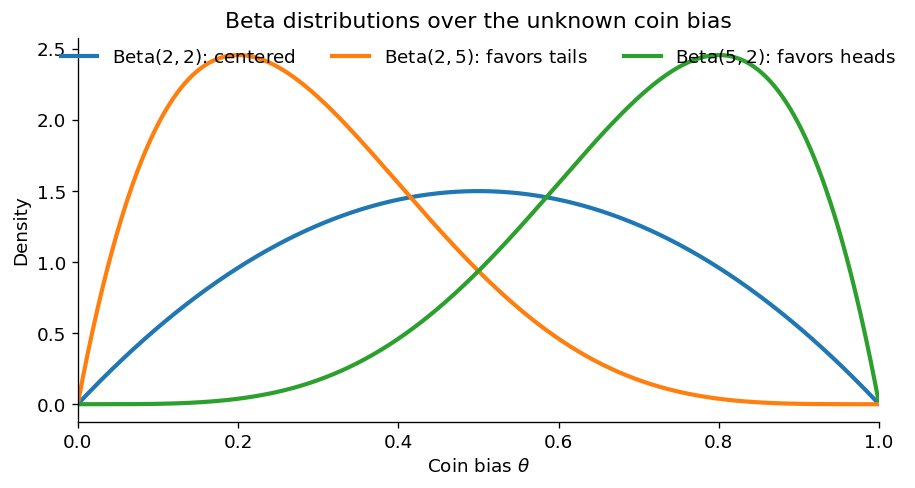

In [14]:
# Representative Beta densities show how alpha and beta encode prior beliefs.
beta_examples = {
    r"$\mathrm{Beta}(2, 2)$: centered": (2, 2),
    r"$\mathrm{Beta}(2, 5)$: favors tails": (2, 5),
    r"$\mathrm{Beta}(5, 2)$: favors heads": (5, 2),
}

theta_grid = np.linspace(0.001, 0.999, 1000)

fig, ax = plt.subplots(figsize=(8, 4.2))
for label, (a, b) in beta_examples.items():
    ax.plot(theta_grid, beta.pdf(theta_grid, a, b), linewidth=2.5, label=label)

ax.set(
    xlabel=r"Coin bias $\theta$",
    ylabel="Density",
    xlim=(0, 1),
    title="Beta distributions over the unknown coin bias",
)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()

save_svg(fig, "coin_model__beta_distribution.svg")
plt.show()

## 2. Bernoulli likelihood for one observed toss

saved figures\coin_model__bernoulli_likelihood.svg


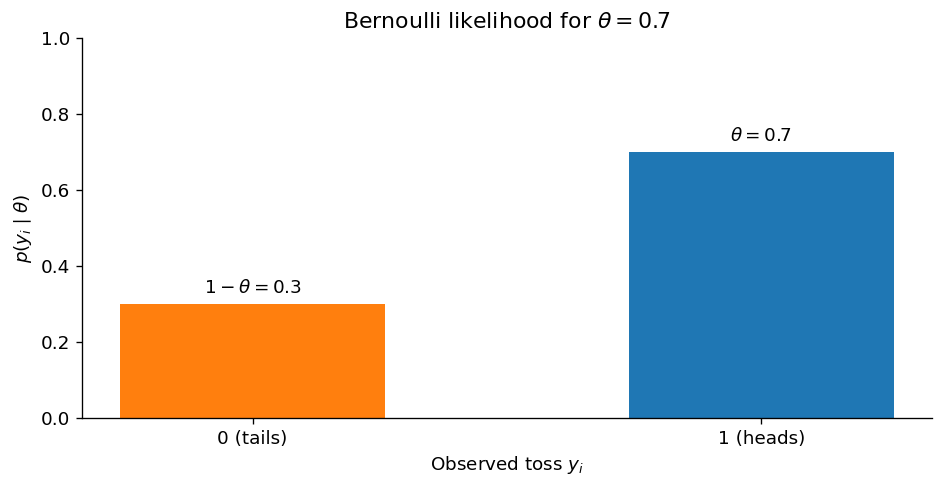

In [15]:
# For a fixed coin bias, a Bernoulli distribution assigns probability to two outcomes.
theta_example = 0.7
outcomes = np.array([0, 1])
probabilities = np.array([1 - theta_example, theta_example])

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(outcomes, probabilities, width=0.52, color=["C1", "C0"])
ax.bar_label(
    bars,
    labels=[r"$1-\theta=0.3$", r"$\theta=0.7$"],
    padding=4,
)
ax.set(
    xlabel=r"Observed toss $y_i$",
    ylabel=r"$p(y_i\mid\theta)$",
    ylim=(0, 1),
    xticks=outcomes,
    xticklabels=["0 (tails)", "1 (heads)"],
    title=r"Bernoulli likelihood for $\theta=0.7$",
)
fig.tight_layout()

save_svg(fig, "coin_model__bernoulli_likelihood.svg")
plt.show()

## 3. Prior × likelihood → posterior

saved figures\coin_model__prior_likelihood_posterior.svg


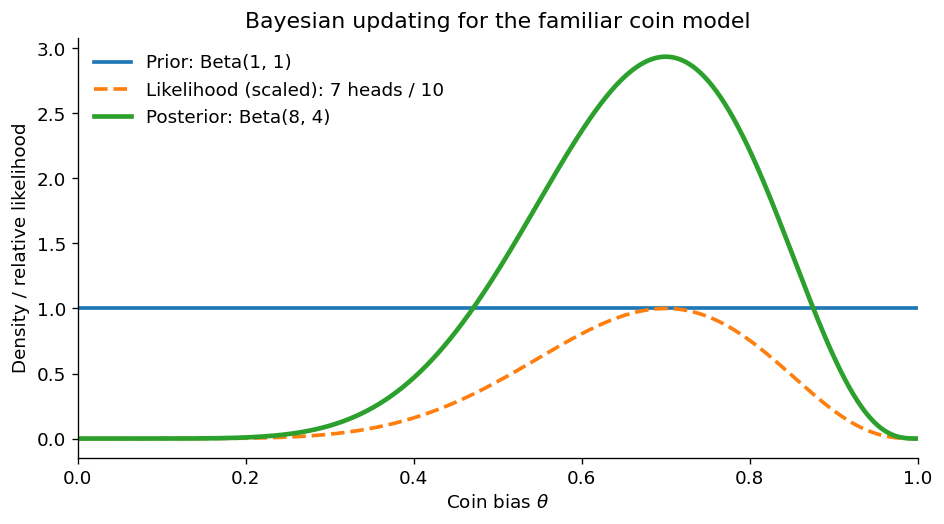

In [16]:
# Familiar Beta-Binomial example
alpha, beta_prior = 1, 1
n, z = 10, 7

theta = np.linspace(0.001, 0.999, 1000)

prior = beta.pdf(theta, alpha, beta_prior)
likelihood = binom.pmf(z, n, theta)
likelihood_scaled = likelihood / likelihood.max() * prior.max()
posterior = beta.pdf(theta, alpha + z, beta_prior + n - z)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta, prior, linewidth=2.2, label=r"Prior: Beta(1, 1)")
ax.plot(theta, likelihood_scaled, linewidth=2.2, linestyle="--",
        label=r"Likelihood (scaled): 7 heads / 10")
ax.plot(theta, posterior, linewidth=2.8, label=r"Posterior: Beta(8, 4)")
ax.set(
    xlabel=r"Coin bias $\theta$",
    ylabel="Density / relative likelihood",
    xlim=(0, 1),
    title="Bayesian updating for the familiar coin model",
)
ax.legend(frameon=False)
fig.tight_layout()

save_svg(fig, "coin_model__prior_likelihood_posterior.svg")
plt.show()

The likelihood is scaled only to make the three curves visible on one axis.  
The posterior itself is the normalized product of prior and likelihood.

## 4. Sequential updating: different priors, same evidence

saved figures\coin_model__sequential_updating.svg


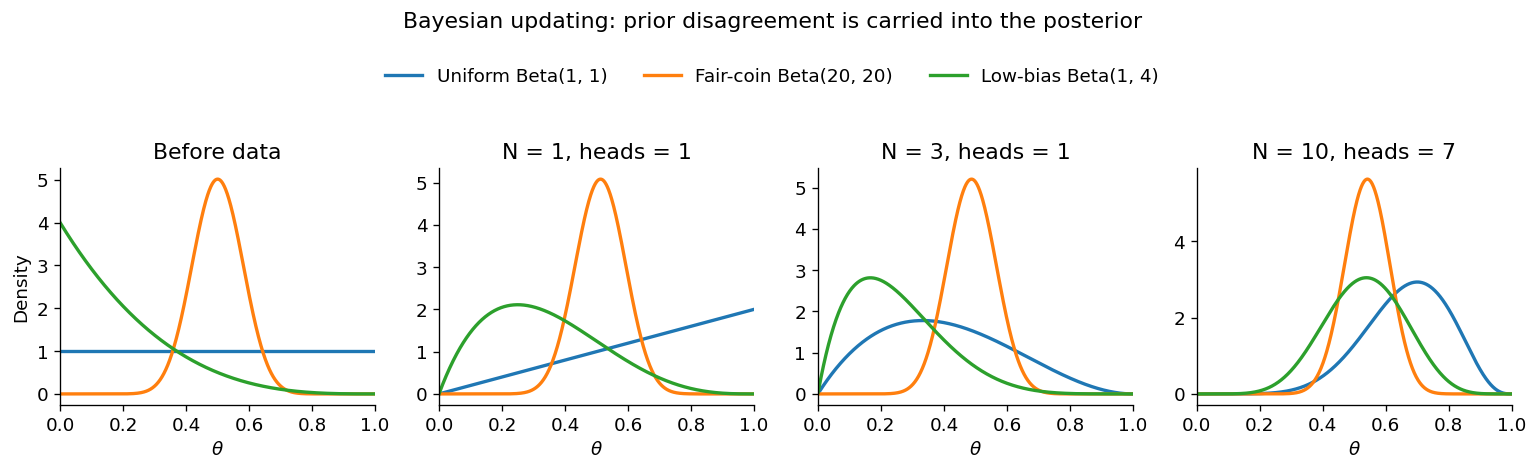

In [17]:
# Start with the same three prior families used in the undergraduate lecture.
priors = {
    "Uniform Beta(1, 1)": (1, 1),
    "Fair-coin Beta(20, 20)": (20, 20),
    "Low-bias Beta(1, 4)": (1, 4),
}

# First three observations reproduce the old sequence: H, T, T.
# The remaining observations give a moderately head-biased sample.
observations = np.array([1, 0, 0, 1, 1, 1, 0, 1, 1, 1], dtype=int)
checkpoints = [0, 1, 3, 10]

fig, axes = plt.subplots(1, len(checkpoints), figsize=(13, 3.3), sharey=False)

for ax, k in zip(axes, checkpoints):
    heads = int(observations[:k].sum())
    tails = k - heads

    for label, (a0, b0) in priors.items():
        density = beta.pdf(theta, a0 + heads, b0 + tails)
        ax.plot(theta, density, linewidth=2, label=label)

    if k == 0:
        ax.set_title("Before data")
    else:
        ax.set_title(f"N = {k}, heads = {heads}")
    ax.set_xlim(0, 1)
    ax.set_xlabel(r"$\theta$")
    if ax is axes[0]:
        ax.set_ylabel("Density")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.08))
fig.suptitle("Bayesian updating: prior disagreement is carried into the posterior", y=1.18)
fig.tight_layout()

save_svg(fig, "coin_model__sequential_updating.svg")
plt.show()

## 5. The posterior is an intermediate object: prediction

saved figures\coin_model__posterior_predictive.svg


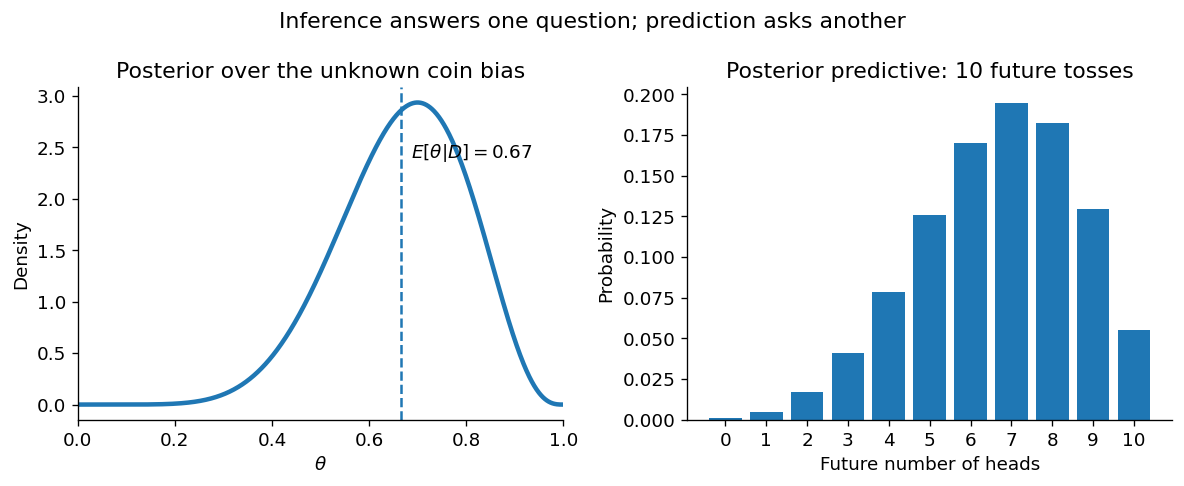

In [18]:
# Continue with the simple uniform-prior example: 7 heads in 10 flips.
a_post, b_post = alpha + z, beta_prior + n - z

# Predict the number of heads in 10 future tosses.
m_future = 10
k_future = np.arange(m_future + 1)
predictive = betabinom.pmf(k_future, m_future, a_post, b_post)

posterior_mean = a_post / (a_post + b_post)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.1))

axes[0].plot(theta, beta.pdf(theta, a_post, b_post), linewidth=2.7)
axes[0].axvline(posterior_mean, linestyle="--", linewidth=1.5)
axes[0].set(
    title="Posterior over the unknown coin bias",
    xlabel=r"$\theta$",
    ylabel="Density",
    xlim=(0, 1),
)
axes[0].text(
    posterior_mean + 0.02,
    axes[0].get_ylim()[1] * 0.78,
    rf"$E[\theta|D]={posterior_mean:.2f}$",
)

axes[1].bar(k_future, predictive)
axes[1].set(
    title="Posterior predictive: 10 future tosses",
    xlabel="Future number of heads",
    ylabel="Probability",
    xticks=k_future,
)

fig.suptitle("Inference answers one question; prediction asks another")
fig.tight_layout()

save_svg(fig, "coin_model__posterior_predictive.svg")
plt.show()

The predictive distribution averages over posterior uncertainty in \(\theta\):

$$
p(\tilde y \mid D)
=
\int p(\tilde y \mid \theta)\,p(\theta\mid D)\,d\theta.
$$

This is the first useful pivot toward probabilistic machine learning: the posterior is often **not the endpoint**.

## 6. Sampling turns posterior integrals into averages

saved figures\coin_model__sampling_monte_carlo.svg


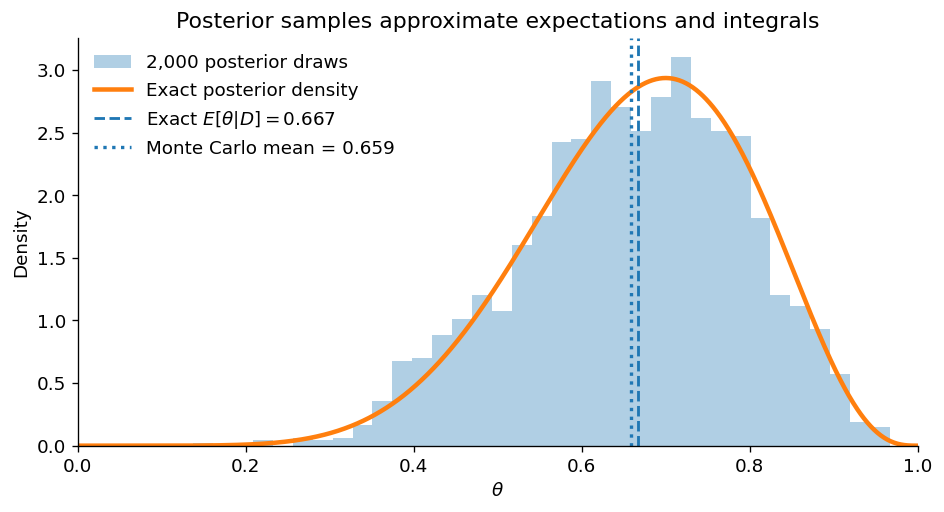

In [19]:
draws = RNG.beta(a_post, b_post, size=2000)

exact_mean = a_post / (a_post + b_post)
mc_mean = draws.mean()

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(draws, bins=35, density=True, alpha=0.35, label="2,000 posterior draws")
ax.plot(theta, beta.pdf(theta, a_post, b_post), linewidth=2.7, label="Exact posterior density")
ax.axvline(exact_mean, linestyle="--", linewidth=1.7,
           label=rf"Exact $E[\theta|D]={exact_mean:.3f}$")
ax.axvline(mc_mean, linestyle=":", linewidth=2.0,
           label=rf"Monte Carlo mean = {mc_mean:.3f}")
ax.set(
    xlabel=r"$\theta$",
    ylabel="Density",
    xlim=(0, 1),
    title="Posterior samples approximate expectations and integrals",
)
ax.legend(frameon=False)
fig.tight_layout()

save_svg(fig, "coin_model__sampling_monte_carlo.svg")
plt.show()

## Figure manifest

`slide_deck.typ` expects these files:

- `figures/coin_model__beta_distribution.svg`
- `figures/coin_model__bernoulli_likelihood.svg`
- `figures/coin_model__prior_likelihood_posterior.svg`
- `figures/coin_model__sequential_updating.svg`
- `figures/coin_model__posterior_predictive.svg`
- `figures/coin_model__sampling_monte_carlo.svg`

The notebook intentionally uses only NumPy, SciPy, and Matplotlib so the author-facing figure layer stays lightweight.
